# Terminating Derivatives: Full vs Partial Unwinds, Counterparty Risk and the Termination Market

Ending a swap early sounds like a simple way to reduce risk, but it often is not. Removing a trade that hedges the rest of the book can leave the bank more exposed, half a termination rarely removes half the risk, and the payment owed at termination is itself a credit exposure until it settles. This notebook works through those effects on a realistic netting set and then looks at how the real swap market terminates trades.

**What it does.** On a SOFR swap netting set simulated with a calibrated Hull–White model, it compares **full and partial terminations**, novation and compression.

For each one it measures the cash settled, the bid-offer cost, the CVA release and the change in EE, EPE and peak PFE (terminating a hedge can *increase* exposure). It also measures the counterparty risk during the termination window.

It trains a **machine-learning pre-trade calculator** (LightGBM and a neural network) on thousands of simulated netting sets to predict the exposure impact of a termination instantly, and finds the cheapest mix of partial terminations that brings PFE under a limit.

Finally, it analyses about a year of public **DTCC swap-data reports**: how often SOFR swaps are terminated early or novated, how far off-market they are when terminated, and which market conditions drive termination activity.

**Data.** The DTCC public swap data repository (CFTC Part 43 cumulative rates files, USD SOFR OIS) and FRED (10-year Treasury yield, Fed funds target).

**Methods.** An OIS curve built from same-day DTCC par swap prints, Hull–White one-factor Monte Carlo with exact bond prices, EE/EPE/PFE and unilateral CVA, and termination economics.

The surrogates (LightGBM and an MLP) are validated with grouped cross-validation against a DV01 rule of thumb. The termination plan uses constrained optimisation (exhaustive search for full terminations, differential evolution for partial ones). Daily termination counts are modelled with a Poisson GLM and LightGBM-Poisson, explained with SHAP.

**Key output.** A termination menu for one counterparty (full or partial, trade by trade), the surrogate's accuracy, the cheapest PFE-reducing termination plan, the settlement-window risk, and the market's termination behaviour and its drivers.

## 1. Why terminations matter for risk management

Banks terminate (unwind) derivatives all the time:

- a client wants out early;
- a limit is breached;
- a counterparty's credit deteriorates;
- trades are compressed (offsetting trades torn up to cut gross notional and capital);
- a trade is novated to a new counterparty.

Each choice has consequences that do not move together:

| Consequence | Full termination | Partial termination |
|---|---|---|
| Cash | the whole mark-to-market is settled | the fraction terminated |
| Bid-offer cost | the whole annuity × spread | proportional |
| Counterparty exposure | the trade leaves the netting set; netting benefit can be **lost** | exposure moves along a curve, often non-monotone |
| CVA | released, or **increased** if the trade was a hedge | in between, but not linearly |
| Settlement risk | the termination payment is owed until it is paid | smaller payment |

Exposure is a *convex function of the portfolio*, so removing half of a trade does not remove half of its risk contribution. That is why a termination is a risk decision, not only a trading one.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import zipfile
import lightgbm as lgb
import shap
import statsmodels.api as sm
from itertools import product
from scipy import optimize
from sklearn.model_selection import GroupKFold
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 23
rng = np.random.default_rng(SEED)
# Monte Carlo paths, quarterly grid, years
N_PATHS, DT_STEP, HORIZON = 4000, 0.25, 15.0
# Hull-White mean reversion (stated assumption)
HW_A = 0.03
RECOVERY = 0.40
# the counterparty's credit spread (BBB/BB+ bank or corporate; assumption)
CPTY_SPREAD_BP = 150
# half bid-offer on the fixed rate by remaining tenor (bp, OIS swaps)
BIDOFFER_BP = {5: 0.25, 10: 0.5, 100: 0.75}
PFE_Q = 0.975
# about one year of daily DTCC files
N_DTCC_DAYS = 250
DTCC_URL = "https://kgc0418-tdw-data-0.s3.amazonaws.com/cftc/eod/CFTC_CUMULATIVE_RATES_{d:%Y_%m_%d}.zip"

print(
    f"lightgbm {lgb.__version__} · shap {shap.__version__} · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

lightgbm 4.7.0 · shap 0.54.1 · run on 2026-10-20


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 3. Market data: one year of DTCC SOFR swap reports

U.S. swap dealers must report every trade, amendment and termination to a swap data repository, and DTCC publishes them daily (CFTC Part 43). Each file is reduced to the USD SOFR OIS reports. The fields that matter here:
- the **action type**: NEWT new, MODI modification, TERM termination;
- the **event type**: TRAD trade, ETRM early termination, NOVA novation, CLRG clearing, COMP compression, EXER exercise;
- dates, notional and fixed rate.

A notional ending in "+" has been capped for publication: it is a lower bound.

The same data give today's **market OIS curve**: the median fixed rate of spot-starting, non-package new trades by tenor over the last five days.

In [3]:
DTCC_DIR = DATA_DIR / "dtcc"
DTCC_DIR.mkdir(exist_ok=True)
KEEP = [
    "Dissemination Identifier",
    "Original Dissemination Identifier",
    "Action type",
    "Event type",
    "Execution Timestamp",
    "Effective Date",
    "Expiration Date",
    "Cleared",
    "Package indicator",
    "Non-standardized term indicator",
    "Notional amount-Leg 1",
    "Notional currency-Leg 1",
    "Fixed rate-Leg 1",
    "Fixed rate-Leg 2",
    "UPI FISN",
    "UPI Underlier Name",
]


def fetch_day(day):
    p = DTCC_DIR / f"{day:%Y_%m_%d}.parquet"
    if p.exists():
        return pd.read_parquet(p)
    r = requests.get(DTCC_URL.format(d=day), timeout=90)
    r.raise_for_status()
    z = zipfile.ZipFile(io.BytesIO(r.content))
    raw = pd.read_csv(z.open(z.namelist()[0]), dtype=str, low_memory=False)
    m = raw["UPI FISN"].fillna("").str.contains("Swap OIS USD") & raw[
        "UPI Underlier Name"
    ].fillna("").str.contains("SOFR", case=False)
    out = raw.loc[m, [c for c in KEEP if c in raw.columns]].copy()
    out["file_date"] = day.isoformat()
    out.to_parquet(p)
    return out


frames, day, tries = [], dt.date.today(), 0
while len(frames) < N_DTCC_DAYS and tries < N_DTCC_DAYS * 1.7:
    day -= dt.timedelta(days=1)
    if day.weekday() >= 5:
        continue
    tries += 1
    try:
        frames.append(fetch_day(day))
    except (requests.RequestException, zipfile.BadZipFile, KeyError):
        # holidays and unpublished days
        continue
rep = pd.concat(frames, ignore_index=True)
numc = lambda s: pd.to_numeric(
    s.fillna("").astype(str).str.replace(",", "").str.rstrip("+"),
    errors="coerce",
)
rep = pd.DataFrame({
    "action": rep["Action type"],
    "event": rep["Event type"],
    "file_date": pd.to_datetime(rep["file_date"]),
    "effective": pd.to_datetime(rep["Effective Date"], errors="coerce"),
    "expiry": pd.to_datetime(rep["Expiration Date"], errors="coerce"),
    "notional": numc(rep["Notional amount-Leg 1"]),
    "capped": rep["Notional amount-Leg 1"].fillna("").str.endswith("+"),
    "rate": (
        numc(rep["Fixed rate-Leg 1"]).fillna(numc(rep["Fixed rate-Leg 2"]))
        * 100
    ),
    "package": rep["Package indicator"].astype(str).str.upper().eq("TRUE"),
    "cleared": rep["Cleared"],
    "currency": rep["Notional currency-Leg 1"],
})
rep = rep[rep["currency"] == "USD"]
rep["tenor"] = (rep["expiry"] - rep["effective"]).dt.days / 365.25
rep["remaining"] = (rep["expiry"] - rep["file_date"]).dt.days / 365.25
rep["kind"] = np.select(
    [
        (rep["action"] == "NEWT") & (rep["event"] == "TRAD"),
        (rep["action"] == "TERM") & (rep["event"] == "ETRM"),
        (rep["action"] == "TERM") & (rep["event"] == "NOVA"),
        (rep["action"] == "TERM") & (rep["event"] == "CLRG"),
        rep["event"] == "COMP",
    ],
    [
        "new trade",
        "early termination",
        "novation (out)",
        "clearing (out)",
        "compression",
    ],
    "other",
)
print(
    f"{rep['file_date'].nunique()} daily files,"
    f" {rep['file_date'].min():%Y-%m-%d} → {rep['file_date'].max():%Y-%m-%d}:"
    f" {len(rep):,} USD SOFR OIS reports"
)
rep.groupby("kind").agg(
    reports=("action", "size"),
    notional_bn=("notional", lambda x: x.sum() / 1e9),
    median_tenor=("tenor", "median"),
).round(1)

249 daily files, 2025-11-04 → 2026-10-19: 1,138,825 USD SOFR OIS reports


,reports,notional_bn,median_tenor
kind,,,
clearing (out),2077,198.70,5.00
compression,4396,"1,148.90",6.60
early termination,15523,"2,307.40",5.00
new trade,964314,"109,600.20",5.00
novation (out),8001,"1,231.70",5.00
other,144514,"23,917.20",5.00


In [4]:
# Market OIS par curve from the last five days of spot-starting, non-package
# new trades
recent = rep[
    (rep["kind"] == "new trade")
    & ~rep["package"]
    & (rep["file_date"] >= rep["file_date"].max() - pd.Timedelta(days=7))
    & ((rep["effective"] - rep["file_date"]).dt.days.between(0, 5))
]
BUCKETS = [1, 2, 3, 5, 7, 10, 15, 20, 30]
recent = recent.assign(
    bucket=[min(BUCKETS, key=lambda b: abs(b - t)) for t in recent["tenor"]]
)
recent = recent[np.abs(recent["tenor"] - recent["bucket"]) < 0.1]
par_ois = recent.groupby("bucket")["rate"].median() / 100
grid_y = np.arange(1, 31)
par_i = np.interp(grid_y, par_ois.index, par_ois.values)
df_ann = []
# annual-pay OIS bootstrap
for n, c in enumerate(par_i, 1):
    df_ann.append((1 - c * sum(df_ann)) / (1 + c))
Z_T = np.concatenate([[0.0], grid_y])
Z_R = np.concatenate([[par_i[0]], -np.log(np.array(df_ann)) / grid_y])


def P0(t):
    t = np.asarray(t, float)
    return np.exp(-np.interp(t, Z_T, Z_R) * t)


def f0(t, h=1e-4):
    return -(np.log(P0(t + h)) - np.log(P0(np.maximum(t - h, 0)))) / (
        t + h - np.maximum(t - h, 0)
    )


dgs10 = fred.get_series(
    "DGS10", observation_start=rep["file_date"].min() - pd.Timedelta(days=400)
).dropna()
# normal vol of the 10y yield
sig10 = dgs10.diff().iloc[-252:].std() * np.sqrt(252) / 100
# match the 10y zero-yield normal vol
HW_SIGMA = sig10 * 10 * HW_A / (1 - np.exp(-10 * HW_A))
print(
    "Market OIS par rates (DTCC, last 5 days, %):",
    ", ".join(f"{int(k)}y {v * 100:.2f}" for k, v in par_ois.items()),
)
print(
    f"10y Treasury normal vol {sig10 * 1e4:.0f} bp/yr → Hull–White σ ="
    f" {HW_SIGMA * 1e4:.0f} bp (a = {HW_A})"
)

Market OIS par rates (DTCC, last 5 days, %): 1y 4.49, 2y 4.62, 3y 4.65, 5y 4.64, 7y 4.66, 10y 4.73, 15y 4.85, 20y 4.92, 30y 4.82
10y Treasury normal vol 67 bp/yr → Hull–White σ = 78 bp (a = 0.03)


## 4. The exposure engine and the counterparty's netting set

Hull–White one-factor: $dr=(\theta(t)-ar)\,dt+\sigma\,dW$, with $\theta$ fitted to today's OIS curve. Each simulated short rate gives exact zero-coupon prices

$$P(t,T)=\frac{P(0,T)}{P(0,t)}\exp\Big\{B(t,T)f(0,t)-\tfrac{\sigma^2}{4a}(1-e^{-2at})B(t,T)^2-B(t,T)\,r(t)\Big\},\qquad B=\frac{1-e^{-a(T-t)}}{a}.$$

The swaps pay fixed annually against compounded SOFR. The floating leg is valued at par at each date, a standard simplification on a quarterly grid.

**Measures, from the bank's side.**
- Expected exposure $EE(t)=E[\max(V_t,0)]$; EPE is its time average over the first year.
- PFE is the 97.5% quantile of $V_t$; the peak PFE is the maximum over time.
- Unilateral CVA: $(1-R)\sum_i EE(t_i)P(0,t_i)[Q(t_{i-1})-Q(t_i)]$, with a flat hazard $s/(1-R)$ from the counterparty's 150 bp spread.

**The netting set.** The counterparty is a corporate client with eight swaps of different vintages. Some are deep in or out of the money, and some offset each other. Old swaps carry the fixed rates of their trade dates.

In [5]:
times = np.arange(DT_STEP, HORIZON + 1e-9, DT_STEP)
alpha = (
    lambda t: f0(t)
    + HW_SIGMA**2 / (2 * HW_A**2) * (1 - np.exp(-HW_A * t)) ** 2
)
x = np.zeros(N_PATHS)
r_paths = np.empty((len(times), N_PATHS))
tprev = 0.0
for k, t in enumerate(times):
    dtk = t - tprev
    x = x * np.exp(-HW_A * dtk) + np.sqrt(
        HW_SIGMA**2 / (2 * HW_A) * (1 - np.exp(-2 * HW_A * dtk))
    ) * rng.standard_normal(N_PATHS)
    r_paths[k] = x + alpha(t)
    tprev = t


def Pt(k, T):
    """
    Zero-coupon prices at grid time times[k] for maturities T (years from
    today), all paths.
    """
    t = times[k] if k >= 0 else 0.0
    if k < 0:
        return np.broadcast_to(
            P0(np.asarray(T)), (N_PATHS,) + np.shape(T)
        ).copy()
    B = (1 - np.exp(-HW_A * (np.asarray(T) - t))) / HW_A
    return (P0(T) / P0(t)) * np.exp(
        B * f0(t)
        - HW_SIGMA**2 / (4 * HW_A) * (1 - np.exp(-2 * HW_A * t)) * B**2
        - np.outer(r_paths[k], B)
    )


def swap_values(start, end, K, notional, payer=True):
    """
    Value of a fixed-vs-SOFR swap today (k = -1) and on every grid date: + for
    the payer of fixed.
    """
    pay = np.arange(start + 1, end + 1e-9, 1.0)
    out = np.zeros((len(times) + 1, N_PATHS))
    for k in range(-1, len(times)):
        t = 0.0 if k < 0 else times[k]
        rem = pay[pay > t + 1e-9]
        if len(rem) == 0:
            continue
        acc = np.diff(np.concatenate([[max(start, rem[0] - 1)], rem]))
        P = Pt(k, rem)
        float_leg = (
            Pt(k, np.array([max(start, t)]))[:, 0] if start > t else 1.0
        ) - P[:, -1]
        v = notional * (float_leg - K * (P * acc).sum(1))
        out[k + 1] = v if payer else -v
    return out


TRADES = pd.DataFrame(
    [
        # name, years since start, years to maturity, fixed rate, notional
        # ($mm), bank pays fixed?
        ("T1 10y payer 2021", -5, 5, 0.0145, 150, True),
        ("T2 7y receiver 2023", -3, 4, 0.0420, 120, False),
        ("T3 15y payer 2024", -2, 13, 0.0385, 80, True),
        ("T4 5y receiver 2025", -1, 4, 0.0360, 200, False),
        ("T5 10y receiver 2025", -1, 9, 0.0395, 100, False),
        ("T6 3y payer 2026", 0, 3, None, 150, True),  # at market
        ("T7 12y receiver 2022", -4, 8, 0.0290, 60, False),
        # at market (truncated at the 15y horizon)
        ("T8 20y payer 2026", 0, 15, None, 50, True),
    ],
    columns=[
        "trade",
        "start",
        "maturity",
        "K",
        "notional_mm",
        "bank_pays_fixed",
    ],
)


def par_rate(start, end):
    pay = np.arange(start + 1, end + 1e-9, 1.0)
    return (P0(max(start, 0)) - P0(end)) / P0(pay).sum()


TRADES["K"] = [
    k if k is not None and not pd.isna(k) else par_rate(0, m)
    for k, m in zip(TRADES["K"], TRADES["maturity"])
]
VAL = {}
for _, tr in TRADES.iterrows():
    # The counterparty's side is the opposite: exposure is measured from the
    # bank's view, payer=bank pays fixed
    VAL[tr["trade"]] = swap_values(
        max(tr["start"], 0) if tr["start"] > 0 else 0.0,
        tr["maturity"],
        tr["K"],
        tr["notional_mm"] * 1e6,
        tr["bank_pays_fixed"],
    )
names = list(VAL)
# trades × (1 + dates) × paths
V = np.stack([VAL[n] for n in names])
lam = CPTY_SPREAD_BP / 1e4 / (1 - RECOVERY)


def annuity(maturity):
    return P0(np.arange(1, maturity + 1e-9, 1.0)).sum()


def metrics(weights):
    """
    Exposure metrics of the netting set when trade i is kept with weight w_i (1
    = untouched, 0 = fully terminated).
    """
    pv = np.tensordot(weights, V, axes=1)  # (1 + dates) × paths
    ee = np.maximum(pv[1:], 0).mean(1)
    pfe = np.quantile(pv[1:], PFE_Q, axis=1)
    Q = np.exp(-lam * np.concatenate([[0], times]))
    cva = (1 - RECOVERY) * np.sum(ee * P0(times) * (Q[:-1] - Q[1:]))
    return {
        "MtM": pv[0].mean(),
        "EPE_1y": ee[times <= 1].mean(),
        "PFE_1y": pfe[np.argmin(np.abs(times - 1))],
        "peak_PFE": pfe.max(),
        "CVA": cva,
        "ee": ee,
        "pfe": pfe,
    }


base = metrics(np.ones(len(names)))
TRADES["MtM_mm"] = [VAL[n][0].mean() / 1e6 for n in names]
TRADES["DV01_k"] = [
    (-1 if p else 1) * tr_n * 1e6 * annuity(m) * 1e-4 / 1e3 * -1
    for p, tr_n, m in zip(
        TRADES["bank_pays_fixed"], TRADES["notional_mm"], TRADES["maturity"]
    )
]
print(
    f"Netting set: MtM {base['MtM'] / 1e6:+.1f}mm (bank's view), EPE(1y)"
    f" {base['EPE_1y'] / 1e6:.1f}mm, peak PFE {base['peak_PFE'] / 1e6:.1f}mm, "
    f"CVA {base['CVA'] / 1e3:,.0f}k · sum of stand-alone peak PFEs"
    f" {sum(metrics(np.eye(len(names))[i])['peak_PFE'] for i in range(len(names))) / 1e6:.1f}mm"
)
TRADES.assign(K=lambda d: (d["K"] * 100).round(2)).round(2)

Netting set: MtM +6.3mm (bank's view), EPE(1y) 7.1mm, peak PFE 24.5mm, CVA 656k · sum of stand-alone peak PFEs 92.1mm


,trade,start,maturity,K,notional_mm,bank_pays_fixed,MtM_mm,DV01_k
0,T1 10y payer 2021,-5,5,1.45,150,True,20.91,65.61
1,T2 7y receiver 2023,-3,4,4.20,120,False,-1.90,-42.92
2,T3 15y payer 2024,-2,13,3.85,80,True,7.29,76.42
3,T4 5y receiver 2025,-1,4,3.60,200,False,-7.46,-71.54
4,T5 10y receiver 2025,-1,9,3.95,100,False,-5.48,-72.15
5,T6 3y payer 2026,0,3,4.65,150,True,0.00,41.15
6,T7 12y receiver 2022,-4,8,2.90,60,False,-7.03,-39.33
7,T8 20y payer 2026,0,15,4.85,50,True,0.00,52.77


## 5. The termination menu: full vs partial, trade by trade

For every trade and every fraction terminated (25%, 50%, 75%, 100%), the bank's P&L of the unwind has three parts:

$$\text{P\&L}=\underbrace{f\,V_i(0)}_{\text{cash at mid (zero-sum)}}\;-\;\underbrace{f\,N_i\,A_i\,h_i}_{\text{bid-offer}}\;+\;\underbrace{\text{CVA}_\text{before}-\text{CVA}_\text{after}}_{\text{CVA release}},$$

where $A_i$ is the remaining annuity and $h_i$ the half bid-offer (0.25–0.75 bp by tenor). The cash at mid only exchanges an asset for cash, so the *economic* P&L is the cost plus the CVA release. Risk effects: change in EPE and in peak PFE.

In [6]:
def half_bo(m):
    return next(v for k, v in BIDOFFER_BP.items() if m <= k) / 1e4


rows = []
for i, n in enumerate(names):
    for f in [0.25, 0.5, 0.75, 1.0]:
        w = np.ones(len(names))
        w[i] = 1 - f
        m_ = metrics(w)
        cost = (
            f
            * TRADES.at[i, "notional_mm"]
            * 1e6
            * annuity(TRADES.at[i, "maturity"])
            * half_bo(TRADES.at[i, "maturity"])
        )
        rows.append({
            "trade": n,
            "fraction": f,
            "cash received ($mm)": f * TRADES.at[i, "MtM_mm"],
            "bid-offer cost ($k)": -cost / 1e3,
            "CVA release ($k)": (base["CVA"] - m_["CVA"]) / 1e3,
            "economic P&L ($k)": (base["CVA"] - m_["CVA"] - cost) / 1e3,
            "ΔEPE 1y ($mm)": (m_["EPE_1y"] - base["EPE_1y"]) / 1e6,
            "Δ PFE at 1y ($mm)": (m_["PFE_1y"] - base["PFE_1y"]) / 1e6,
            "Δ peak PFE ($mm)": (m_["peak_PFE"] - base["peak_PFE"]) / 1e6,
        })
menu = pd.DataFrame(rows)
full = menu[menu["fraction"] == 1.0].set_index("trade")
half = menu[menu["fraction"] == 0.5].set_index("trade")
lin_check = (
    half["ΔEPE 1y ($mm)"] / full["ΔEPE 1y ($mm)"].replace(0, np.nan)
).rename("ΔEPE of a 50% termination / ΔEPE of a full one")
print(
    "Exposure-increasing full terminations (terminating a hedge): EPE ↑ for",
    ", ".join(full.index[full["ΔEPE 1y ($mm)"] > 0]),
    "· peak PFE ↑ for",
    ", ".join(full.index[full["Δ peak PFE ($mm)"] > 0]) or "none",
)
display(full.round(2))
lin_check.round(2).to_frame().T

Exposure-increasing full terminations (terminating a hedge): EPE ↑ for T4 5y receiver 2025, T5 10y receiver 2025, T6 3y payer 2026, T7 12y receiver 2022, T8 20y payer 2026 · peak PFE ↑ for T5 10y receiver 2025, T7 12y receiver 2022


,fraction,cash received ($mm),bid-offer cost ($k),CVA release ($k),economic P&L ($k),ΔEPE 1y ($mm),Δ PFE at 1y ($mm),Δ peak PFE ($mm)
trade,,,,,,,,
T1 10y payer 2021,1.00,20.91,-16.40,327.64,311.23,-7.10,-11.25,0.00
T2 7y receiver 2023,1.00,-1.90,-10.73,38.52,27.79,-0.17,6.43,0.00
T3 15y payer 2024,1.00,7.29,-57.31,444.24,386.93,-4.94,0.92,-11.48
T4 5y receiver 2025,1.00,-7.46,-17.89,-71.08,-88.97,3.83,13.93,0.00
T5 10y receiver 2025,1.00,-5.48,-36.08,-272.75,-308.83,3.80,13.72,7.31
T6 3y payer 2026,1.00,0.00,-10.29,-100.96,-111.25,2.48,2.67,0.00
T7 12y receiver 2022,1.00,-7.03,-19.66,-317.87,-337.53,5.96,10.86,3.64
T8 20y payer 2026,1.00,0.00,-39.58,92.72,53.14,0.83,5.27,-8.72


trade,T1 10y payer 2021,T2 7y receiver 2023,T3 15y payer 2024,T4 5y receiver 2025,T5 10y receiver 2025,T6 3y payer 2026,T7 12y receiver 2022,T8 20y payer 2026
ΔEPE of a 50% termination / ΔEPE of a full one,0.98,0.52,0.60,0.50,0.50,0.50,0.50,0.49


### Novation, compression and the termination window

- **Novation.** The trade moves to a new counterparty at its current value. For the original counterparty this is a full termination with no cash at mid between the two banks, and the exposure moves to the new name.
- **Compression.** Two offsetting trades are torn up together. Here that means a partial tear-up of a payer and a receiver of similar maturity, sized to keep the net DV01 unchanged.
- **The termination window.** Between the agreement (price locked) and settlement (typically T+2 to T+5), the bank is exposed to the counterparty's default on the termination payment if it is owed money. It is also exposed to the whole netting set's moves if settlement fails and the ISDA close-out has to be valued later at market. The table shows that risk at 2, 5 and 10 business days.

In [7]:
# Compression: tear up a matching share of T1 (payer, 5y left) and T4
# (receiver, 4y left) so that net DV01 stays the same
dv = TRADES.set_index("trade")["DV01_k"]
f1 = 0.5
f4 = min(
    1.0, f1 * abs(dv["T1 10y payer 2021"]) / abs(dv["T4 5y receiver 2025"])
)
w = np.ones(len(names))
w[0] -= f1
w[3] -= f4
mc = metrics(w)
gross_before = TRADES["notional_mm"].sum()
gross_after = (
    gross_before
    - f1 * TRADES.at[0, "notional_mm"]
    - f4 * TRADES.at[3, "notional_mm"]
)
comp = pd.Series({
    "gross notional before ($mm)": gross_before,
    "gross notional after ($mm)": gross_after,
    "net DV01 change ($k)": -(f1 * dv.iloc[0] + f4 * dv.iloc[3]),
    "Δ peak PFE ($mm)": (mc["peak_PFE"] - base["peak_PFE"]) / 1e6,
    "CVA release ($k)": (base["CVA"] - mc["CVA"]) / 1e3,
})

# Termination window: change in value of the termination amount and of the
# netting set over h business days
win = []
for h in [2, 5, 10]:
    # quarterly grid → use the first grid step scaled by sqrt(time)
    k = max(0, int(round(h / 63)) - 1)
    scale = np.sqrt(h / 252 / DT_STEP)
    d_set = (
        np.tensordot(np.ones(len(names)), V, axes=1)[1] - base["MtM"]
    ) * scale
    pd_h = 1 - np.exp(-lam * h / 252)
    owed = max(TRADES.at[0, "MtM_mm"], 0) * 1e6
    win.append({
        "window (business days)": h,
        "99% move in netting-set value ($mm)": (
            np.quantile(np.abs(d_set), 0.99) / 1e6
        ),
        "PD in window": pd_h,
        "expected loss on T1 termination payment ($k)": (
            pd_h * (1 - RECOVERY) * owed / 1e3
        ),
        "loss if default, 99% ($mm)": (
            (1 - RECOVERY) * owed + np.quantile(np.maximum(d_set, 0), 0.99)
        ) / 1e6,
    })
display(comp.round(2).to_frame("compression of T1 vs T4"))
pd.DataFrame(win).set_index("window (business days)").round(4)

,compression of T1 vs T4
gross notional before ($mm),910.00
gross notional after ($mm),743.29
net DV01 change ($k),-0.00
Δ peak PFE ($mm),0.00
CVA release ($k),280.77


,99% move in netting-set value ($mm),PD in window,expected loss on T1 termination payment ($k),"loss if default, 99% ($mm)"
window (business days),,,,
2,0.12,0.00,2.49,12.66
5,0.19,0.00,6.22,12.73
10,0.26,0.00,12.44,12.81


## 6. A machine-learning pre-trade calculator for terminations

Re-running a Monte Carlo engine for every "what if we terminate X?" question is slow on real books: thousands of counterparties, each with hundreds of trades. A surrogate learns the mapping from *cheap, static* trade and portfolio features to the exposure impact.

**Training data.** 400 random netting sets, each with 3–12 swaps of random direction, tenor, notional and off-market fixed rate, re-using the simulated rate paths. Each set gets 12 random termination proposals: a single trade, fully or partially. That is 4,800 examples.

**Features.** All are available without simulation:
- the fraction terminated;
- the trade's MtM, DV01, maturity and fixed-rate moneyness;
- the netting set's MtM, net DV01, gross DV01 and trade count;
- whether the trade's DV01 has the same sign as the set's (**hedge or not**);
- the set's net DV01 after the termination.

**Targets.** The relative change in EPE and in peak PFE.

**Models.**
- LightGBM;
- an MLP neural network (scikit-learn);
- a **DV01 rule of thumb** used on many desks: exposure scales with the absolute net DV01.

**Validation.** Grouped by netting set: the model is tested on portfolios it has never seen.

In [8]:
def random_set(n):
    mats = rng.integers(2, 16, n).astype(float)
    starts = -rng.integers(0, 6, n).astype(float)
    pay = rng.random(n) < 0.5
    notl = rng.choice([25, 50, 75, 100, 150, 200, 300], n).astype(float)
    Ks = np.array([par_rate(0, m) for m in mats]) + rng.normal(0, 0.009, n)
    vals = np.stack([
        swap_values(0.0, m, k, N * 1e6, p)
        for m, k, N, p in zip(mats, Ks, notl, pay)
    ])
    dv01 = np.array([
        (1 if p else -1) * N * 1e6 * annuity(m) * 1e-4
        for p, N, m in zip(pay, notl, mats)
    ])
    return vals, mats, Ks, notl, pay, dv01


def exp_metrics(Vs, w):
    pv = np.tensordot(w, Vs, axes=1)[1:]
    return (
        np.maximum(pv, 0)[times <= 1].mean(),
        np.quantile(pv, PFE_Q, axis=1).max(),
    )


samples = []
t0 = time.time()
for s in range(400):
    n = int(rng.integers(3, 13))
    Vs, mats, Ks, notl, pay, dv01 = random_set(n)
    epe0, pfe0 = exp_metrics(Vs, np.ones(n))
    mtm = Vs[:, 0].mean(1)
    for _ in range(12):
        i = int(rng.integers(n))
        f = float(rng.choice([0.25, 0.5, 0.75, 1.0]))
        w = np.ones(n)
        w[i] -= f
        epe1, pfe1 = exp_metrics(Vs, w)
        samples.append({
            "set": s,
            "fraction": f,
            "trade_mtm": mtm[i] / 1e6,
            "trade_dv01": dv01[i] / 1e3,
            "trade_maturity": mats[i],
            "moneyness_bp": (
                (Ks[i] - par_rate(0, mats[i])) * 1e4 * (1 if pay[i] else -1)
            ),
            "set_mtm": mtm.sum() / 1e6,
            "set_net_dv01": dv01.sum() / 1e3,
            "set_gross_dv01": np.abs(dv01).sum() / 1e3,
            "n_trades": n,
            "is_hedge": float(np.sign(dv01[i]) != np.sign(dv01.sum())),
            "net_dv01_after": (dv01.sum() - f * dv01[i]) / 1e3,
            "rule_of_thumb": (
                abs(dv01.sum() - f * dv01[i]) / max(abs(dv01.sum()), 1) - 1
            ),
            "d_epe": epe1 / max(epe0, 1) - 1,
            "d_pfe": pfe1 / max(pfe0, 1) - 1,
        })
S = pd.DataFrame(samples)
FE = [
    "fraction",
    "trade_mtm",
    "trade_dv01",
    "trade_maturity",
    "moneyness_bp",
    "set_mtm",
    "set_net_dv01",
    "set_gross_dv01",
    "n_trades",
    "is_hedge",
    "net_dv01_after",
]
res, sur_models = {}, {}
for target in ["d_epe", "d_pfe"]:
    y = S[target].clip(-1, 3).to_numpy()
    pred = {"LightGBM": np.zeros(len(S)), "MLP": np.zeros(len(S))}
    for tr, te in GroupKFold(5).split(S, groups=S["set"]):
        g = lgb.LGBMRegressor(
            n_estimators=800,
            learning_rate=0.03,
            num_leaves=31,
            min_child_samples=20,
            subsample=0.8,
            subsample_freq=1,
            colsample_bytree=0.9,
            verbose=-1,
            random_state=SEED,
        ).fit(S.loc[tr, FE], y[tr])
        pred["LightGBM"][te] = g.predict(S.loc[te, FE])
        sc = StandardScaler().fit(S.loc[tr, FE])
        mlp = MLPRegressor(
            hidden_layer_sizes=(64, 64),
            alpha=1e-3,
            learning_rate_init=1e-3,
            max_iter=600,
            early_stopping=True,
            random_state=SEED,
        )
        pred["MLP"][te] = mlp.fit(sc.transform(S.loc[tr, FE]), y[tr]).predict(
            sc.transform(S.loc[te, FE])
        )
    pred["DV01 rule of thumb"] = S["rule_of_thumb"].clip(-1, 3).to_numpy()
    for m_, p in pred.items():
        res[(target, m_)] = {
            "R²": 1 - np.mean((y - p) ** 2) / np.var(y),
            "MAE (pp)": np.mean(np.abs(y - p)) * 100,
            "sign right (%)": np.mean(np.sign(p) == np.sign(y)) * 100,
        }
    S[f"pred_{target}"] = pred["LightGBM"]
    sur_models[target] = lgb.LGBMRegressor(
        n_estimators=800,
        learning_rate=0.03,
        num_leaves=31,
        min_child_samples=20,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.9,
        verbose=-1,
        random_state=SEED,
    ).fit(S[FE], y)
sur_score = pd.DataFrame(res).T
sv = shap.TreeExplainer(sur_models["d_pfe"]).shap_values(S[FE])
sur_shap = pd.Series(np.abs(sv).mean(0), index=FE).sort_values(ascending=False)
t_engine = (time.time() - t0) / len(S)
print(
    f"{len(S):,} termination proposals on {S['set'].nunique()} netting sets"
    f" ({t_engine * 1e3:.0f} ms per engine evaluation incl. set building) ·"
    f" exposure increases in {(S['d_pfe'] > 0).mean():.0%} of proposals"
)
sur_score.round(3)

4,800 termination proposals on 400 netting sets (24 ms per engine evaluation incl. set building) · exposure increases in 28% of proposals


R²  MAE (pp)  sign right (%)
d_epe LightGBM            0.65     28.37           86.27
      MLP                 0.63     32.02           79.92
      DV01 rule of thumb -0.12     56.29           69.33
d_pfe LightGBM            0.33     12.70           66.90
      MLP                 0.29     14.26           61.67
      DV01 rule of thumb -3.23     31.68           71.23

## 7. The cheapest way to bring PFE under a limit: full vs partial terminations

Suppose the credit department cuts the counterparty's PFE limit to **80% of the current peak**. Which terminations reach it at the lowest transaction cost (bid-offer)? The CVA release and the cash that changes hands are reported alongside, because they matter to the client relationship and to the desk, but they are not what the plan minimises.
- **Full terminations only:** all $2^8=256$ subsets are evaluated exactly with the engine.
- **Partial terminations:** each trade can be kept with any weight in $[0,1]$. Differential evolution minimises cost with a penalty for breaching the limit, then the solution is re-checked with the engine.

In [9]:
LIMIT = 0.8 * base["peak_PFE"]
N_ = TRADES["notional_mm"].to_numpy() * 1e6
A_ = np.array([annuity(m) for m in TRADES["maturity"]])
H_ = np.array([half_bo(m) for m in TRADES["maturity"]])


def plan_cost(w):
    """
    Transaction cost of a plan (bid-offer on the terminated fractions); the CVA
    effect is reported, not optimised.
    """
    m_ = metrics(w)
    return np.sum((1 - w) * N_ * A_ * H_), m_


best_full = None
for combo in product([0, 1], repeat=len(names)):
    w = 1 - np.array(combo, float)
    c, m_ = plan_cost(w)
    if m_["peak_PFE"] <= LIMIT and (best_full is None or c < best_full[0]):
        best_full = (c, w, m_)


def objective(w):
    c, m_ = plan_cost(np.asarray(w))
    return c + 1e3 * max(0.0, m_["peak_PFE"] - LIMIT) / 1e3 * 50


de = optimize.differential_evolution(
    objective,
    bounds=[(0, 1)] * len(names),
    seed=SEED,
    maxiter=60,
    popsize=12,
    tol=1e-6,
    polish=False,
)
w_part = np.round(de.x, 3)
# Clean-up: drop "dust" terminations below 2% of a trade if the plan still
# meets the limit, then scale down the largest one while it does
for i in np.argsort(1 - w_part):
    if 0 < 1 - w_part[i] < 0.02:
        trial = w_part.copy()
        trial[i] = 1.0
        if metrics(trial)["peak_PFE"] <= LIMIT:
            w_part = trial
c_part, m_part = plan_cost(w_part)
plan_row = lambda w, c, m_: {
    **{n: 1 - wi for n, wi in zip(names, w)},
    "bid-offer cost ($k)": c / 1e3,
    "gross notional terminated ($mm)": np.sum((1 - w) * TRADES["notional_mm"]),
    "cash settled at mid ($mm)": np.sum((1 - w) * TRADES["MtM_mm"]),
    "CVA release ($k)": (base["CVA"] - m_["CVA"]) / 1e3,
    "peak PFE after ($mm)": m_["peak_PFE"] / 1e6,
}
plans = pd.DataFrame({
    "full terminations only": plan_row(
        best_full[1], best_full[0], best_full[2]
    ),
    "partial terminations": plan_row(w_part, c_part, m_part),
})
print(
    f"Limit: peak PFE ≤ {LIMIT / 1e6:.1f}mm (from"
    f" {base['peak_PFE'] / 1e6:.1f}mm) · partial plan meets the limit:"
    f" {m_part['peak_PFE'] <= LIMIT * 1.001}"
)
plans.round(2)

Limit: peak PFE ≤ 19.6mm (from 24.5mm) · partial plan meets the limit: True


,full terminations only,partial terminations
T1 10y payer 2021,0.00,0.04
T2 7y receiver 2023,0.00,0.00
T3 15y payer 2024,0.00,0.05
T4 5y receiver 2025,0.00,0.00
T5 10y receiver 2025,0.00,0.00
T6 3y payer 2026,0.00,0.00
T7 12y receiver 2022,0.00,0.02
T8 20y payer 2026,1.00,0.42
bid-offer cost ($k),39.58,20.30
gross notional terminated ($mm),50.00,32.25


## 8. The real termination market (DTCC SOFR swaps)

Three questions on about a year of public reports:
1. **How much is terminated?** Daily counts and notional of early terminations and novations relative to new trades.
2. **Which trades are terminated?** Their age, remaining tenor, and how far their fixed rate is from the same-day par rate. That gap is a direct measure of the **value transferred at termination**, approximately $(K-\text{par})\times$ annuity per unit of notional; public data do not show the direction.
3. **What drives termination activity?** Daily early-termination counts are modelled with a Poisson GLM and a LightGBM-Poisson model on:
   - rate volatility: the absolute daily change and 20-day realised volatility of the 10-year Treasury, and its 5-day change;
   - trading activity: the new-trade count;
   - calendar effects: month-end, quarter-end, weekday, and days with a Fed target change.

The models are trained on the first 65% of days and tested on the rest.

In [10]:
daily = rep.pivot_table(
    index="file_date",
    columns="kind",
    values="notional",
    aggfunc=["size", "sum"],
).fillna(0)
daily.columns = [f"{a}|{b}" for a, b in daily.columns]
daily = daily.rename(
    columns=lambda c: c.replace("size|", "n_").replace("sum|", "notl_")
)
dd = pd.DataFrame(index=daily.index)
dd["n_etrm"], dd["n_new"] = daily.get("n_early termination", 0), daily.get(
    "n_new trade", 0
)
dd["n_nova"] = daily.get("n_novation (out)", 0)
dd["etrm_share_notional"] = daily.get("notl_early termination", 0) / daily.get(
    "notl_new trade", 1
).replace(0, np.nan)
y10 = dgs10.reindex(pd.date_range(dgs10.index.min(), dd.index.max())).ffill()
dd["abs_d10y_bp"] = (y10.diff().abs() * 100).reindex(dd.index)
dd["rv20_bp"] = (y10.diff() * 100).rolling(20).std().reindex(dd.index)
dd["d10y_5d_bp"] = (y10.diff(5) * 100).reindex(dd.index)
bdays = pd.Series(dd.index, index=dd.index)
dd["month_end"] = (
    bdays.groupby(bdays.dt.to_period("M")).rank(ascending=False) <= 2
).astype(int)
dd["quarter_end"] = (
    dd["month_end"].astype(bool) & dd.index.month.isin([3, 6, 9, 12])
).astype(int)
dd["weekday"] = dd.index.weekday
fedt = fred.get_series(
    "DFEDTARU", observation_start=dd.index.min() - pd.Timedelta(days=10)
).ffill()
chg = fedt.diff().fillna(0) != 0
dd["fed_move"] = (
    chg.reindex(dd.index, method="ffill").fillna(False).astype(int)
)
dd["log_new"] = np.log1p(dd["n_new"])
dd = dd.dropna()
DF_ = [
    "abs_d10y_bp",
    "rv20_bp",
    "d10y_5d_bp",
    "log_new",
    "month_end",
    "quarter_end",
    "weekday",
    "fed_move",
]
cut = int(len(dd) * 0.65)
trd, ted = dd.iloc[:cut], dd.iloc[cut:]
glm = sm.GLM(
    trd["n_etrm"],
    sm.add_constant(
        trd[DF_].assign(weekday=lambda d: d["weekday"].astype(float))
    ),
    family=sm.families.Poisson(),
).fit()
p_glm = glm.predict(
    sm.add_constant(
        ted[DF_].assign(weekday=lambda d: d["weekday"].astype(float)),
        has_constant="add",
    )
)
gbm = lgb.LGBMRegressor(
    objective="poisson",
    n_estimators=400,
    learning_rate=0.03,
    num_leaves=7,
    min_child_samples=10,
    verbose=-1,
    random_state=SEED,
).fit(trd[DF_], trd["n_etrm"])
p_gbm = gbm.predict(ted[DF_])
dev = lambda y, mu: 2 * np.sum(
    np.where(y > 0, y * np.log(np.where(y > 0, y, 1) / mu), 0) - (y - mu)
)
null = np.full(len(ted), trd["n_etrm"].mean())
mkt_score = pd.DataFrame({
    "Poisson deviance (test)": {
        "constant": dev(ted["n_etrm"], null),
        "Poisson GLM": dev(ted["n_etrm"], p_glm),
        "LightGBM-Poisson": dev(ted["n_etrm"], p_gbm),
    },
    "correlation with actual": {
        "constant": np.nan,
        "Poisson GLM": np.corrcoef(ted["n_etrm"], p_glm)[0, 1],
        "LightGBM-Poisson": np.corrcoef(ted["n_etrm"], p_gbm)[0, 1],
    },
})
glm_coef = pd.DataFrame({"coef": glm.params, "z": glm.tvalues}).drop("const")
mkt_shap = pd.Series(
    np.abs(shap.TreeExplainer(gbm).shap_values(dd[DF_])).mean(0), index=DF_
).sort_values(ascending=False)
print(
    f"{len(dd)} trading days · early terminations per day: median"
    f" {dd['n_etrm'].median():.0f} (new trades {dd['n_new'].median():.0f});"
    f" terminated notional = {dd['etrm_share_notional'].median():.1%} of"
    " new-trade notional on the median day"
)
display(mkt_score.round(3))
glm_coef.round(3)

247 trading days · early terminations per day: median 58 (new trades 4035); terminated notional = 1.6% of new-trade notional on the median day


,Poisson deviance (test),correlation with actual
constant,908.08,NaN
Poisson GLM,501.20,0.59
LightGBM-Poisson,644.32,0.50


,coef,z
abs_d10y_bp,0.02,3.71
rv20_bp,-0.05,-3.62
d10y_5d_bp,-0.00,-1.84
log_new,0.62,17.45
month_end,-0.09,-1.91
quarter_end,-0.28,-2.97
weekday,-0.05,-6.17
fed_move,0.23,2.12


In [11]:
# Off-market-ness: fixed rate vs same-day par for the same remaining-tenor
# bucket
newt = rep[
    (rep["kind"] == "new trade")
    & ~rep["package"]
    & ((rep["effective"] - rep["file_date"]).dt.days.between(0, 5))
].copy()
newt["bucket"] = [
    min(BUCKETS, key=lambda b: abs(b - t)) for t in newt["tenor"]
]
par_day = (
    newt[np.abs(newt["tenor"] - newt["bucket"]) < 0.25]
    .groupby(["file_date", "bucket"])["rate"]
    .median()
)
term = rep[
    rep["kind"].isin(["early termination", "novation (out)"])
    & rep["rate"].notna()
    & (rep["remaining"] > 0.5)
].copy()
term["bucket"] = [
    min(BUCKETS, key=lambda b: abs(b - t)) for t in term["remaining"]
]
term["par"] = [
    par_day.get((d_, b_), np.nan)
    for d_, b_ in zip(term["file_date"], term["bucket"])
]
term["off_bp"] = (term["rate"] - term["par"]) * 100
term["age_y"] = (term["file_date"] - term["effective"]).dt.days / 365.25
term["value_pct"] = (
    term["off_bp"].abs()
    / 1e4
    * [annuity(min(t, 30)) for t in term["remaining"]]
    * 100
)
newt_off = newt.assign(
    par=[
        par_day.get((d_, b_), np.nan)
        for d_, b_ in zip(newt["file_date"], newt["bucket"])
    ]
)
newt_off["off_bp"] = (newt_off["rate"] - newt_off["par"]) * 100
term = term.dropna(subset=["off_bp"])
offm = pd.DataFrame({
    k: {
        "reports": len(g),
        "median |K − par| (bp)": g["off_bp"].abs().median(),
        "75th pct |K − par| (bp)": g["off_bp"].abs().quantile(0.75),
        "median age (years)": g["age_y"].median() if "age_y" in g else np.nan,
        "share terminated within 30 days of start (%)": (
            (g["age_y"] < 30 / 365.25).mean() * 100 if "age_y" in g else np.nan
        ),
        "median remaining tenor (y)": (
            g["remaining"].median() if "remaining" in g else np.nan
        ),
        "median value transferred (% notional)": (
            g["value_pct"].median() if "value_pct" in g else np.nan
        ),
    }
    for k, g in [
        ("early termination", term[term["kind"] == "early termination"]),
        ("novation (out)", term[term["kind"] == "novation (out)"]),
        ("new trades (reference)", newt_off.dropna(subset=["off_bp"])),
    ]
}).T
offm.round(2)

,reports,median |K − par| (bp),75th pct |K − par| (bp),median age (years),share terminated within 30 days of start (%),median remaining tenor (y),median value transferred (% notional)
early termination,"14,791.00",7.94,29.17,-0.01,80.68,6.77,0.34
novation (out),"7,543.00",4.70,17.05,0.00,92.55,5.18,0.17
new trades (reference),"192,656.00",1.79,5.62,NaN,NaN,5.00,NaN


## 9. Charts

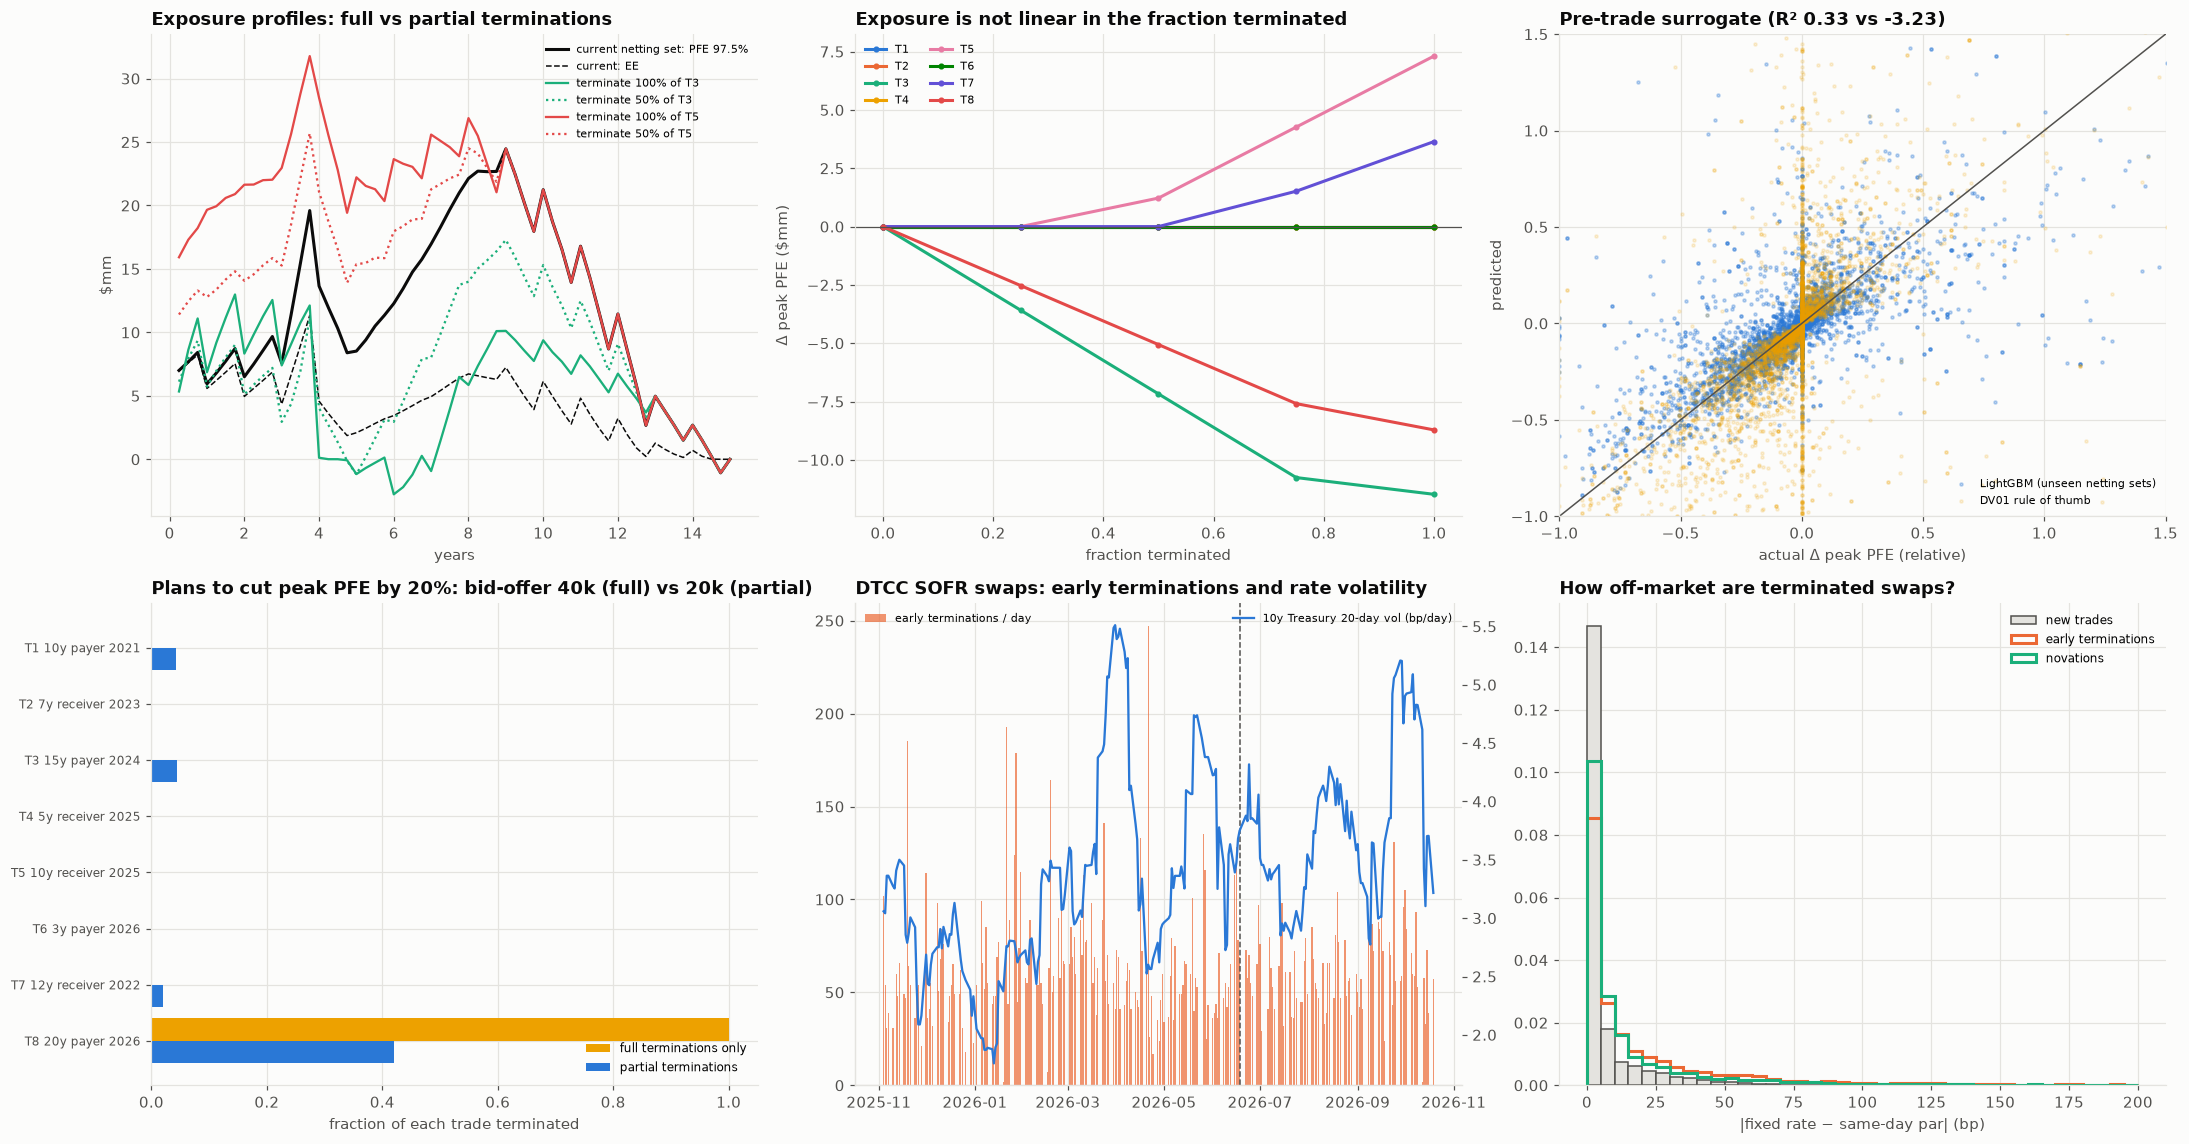

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(20, 10.5))
ax = axes[0, 0]
ax.plot(
    times,
    base["pfe"] / 1e6,
    color=INK,
    lw=2,
    label="current netting set: PFE 97.5%",
)
ax.plot(times, base["ee"] / 1e6, color=INK, lw=1, ls="--", label="current: EE")
hedge_tr = full["Δ peak PFE ($mm)"].idxmax()
risk_tr = full["Δ peak PFE ($mm)"].idxmin()
for n, c in [(risk_tr, PALETTE[2]), (hedge_tr, PALETTE[7])]:
    i = names.index(n)
    for f, ls in [(1.0, "-"), (0.5, ":")]:
        w = np.ones(len(names))
        w[i] = 1 - f
        ax.plot(
            times,
            metrics(w)["pfe"] / 1e6,
            color=c,
            ls=ls,
            lw=1.5,
            label=f"terminate {f:.0%} of {n.split()[0]}",
        )
ax.set_xlabel("years")
ax.set_ylabel("$mm")
ax.set_title("Exposure profiles: full vs partial terminations")
ax.legend(fontsize=7)
ax = axes[0, 1]
for n, c in zip(names, PALETTE * 2):
    g = menu[menu["trade"] == n]
    ax.plot(
        np.concatenate([[0], g["fraction"]]),
        np.concatenate([[0], g["Δ peak PFE ($mm)"]]),
        "o-",
        color=c,
        ms=3,
        label=n.split()[0],
    )
ax.axhline(0, color=INK_2, lw=0.8)
ax.set_xlabel("fraction terminated")
ax.set_ylabel("Δ peak PFE ($mm)")
ax.set_title("Exposure is not linear in the fraction terminated")
ax.legend(fontsize=7, ncol=2)
ax = axes[0, 2]
lim_ = (-1, 1.5)
ax.scatter(
    S["d_pfe"],
    S["pred_d_pfe"],
    s=4,
    alpha=0.3,
    color=PALETTE[0],
    label="LightGBM (unseen netting sets)",
)
ax.scatter(
    S["d_pfe"],
    S["rule_of_thumb"],
    s=4,
    alpha=0.15,
    color=PALETTE[3],
    label="DV01 rule of thumb",
)
ax.plot(lim_, lim_, color=INK_2, lw=1)
ax.set_xlim(lim_)
ax.set_ylim(lim_)
ax.set_xlabel("actual Δ peak PFE (relative)")
ax.set_ylabel("predicted")
ax.set_title(
    "Pre-trade surrogate (R²"
    f" {sur_score.loc[('d_pfe', 'LightGBM'), 'R²']:.2f} vs"
    f" {sur_score.loc[('d_pfe', 'DV01 rule of thumb'), 'R²']:.2f})"
)
ax.legend(fontsize=7)
ax = axes[1, 0]
pl = plans.loc[names].astype(float)
yy = np.arange(len(names))
ax.barh(
    yy - 0.2,
    pl["full terminations only"],
    height=0.4,
    color=PALETTE[3],
    label="full terminations only",
)
ax.barh(
    yy + 0.2,
    pl["partial terminations"],
    height=0.4,
    color=PALETTE[0],
    label="partial terminations",
)
ax.set_yticks(yy)
ax.set_yticklabels(names, fontsize=8)
ax.invert_yaxis()
ax.set_xlim(0, 1.05)
ax.set_xlabel("fraction of each trade terminated")
ax.set_title(
    "Plans to cut peak PFE by 20%: bid-offer"
    f" {plans.loc['bid-offer cost ($k)', 'full terminations only']:.0f}k"
    " (full) vs"
    f" {plans.loc['bid-offer cost ($k)', 'partial terminations']:.0f}k"
    " (partial)"
)
ax.legend(fontsize=8, loc="lower right")
ax = axes[1, 1]
ax.bar(
    dd.index,
    dd["n_etrm"],
    color=PALETTE[1],
    alpha=0.7,
    label="early terminations / day",
)
ax2 = ax.twinx()
ax2.plot(
    dd.index,
    dd["rv20_bp"],
    color=PALETTE[0],
    lw=1.5,
    label="10y Treasury 20-day vol (bp/day)",
)
ax2.grid(False)
ax.axvline(dd.index[cut], color=INK_2, ls="--", lw=1)
ax.set_title("DTCC SOFR swaps: early terminations and rate volatility")
ax.legend(fontsize=7, loc="upper left")
ax2.legend(fontsize=7, loc="upper right")
ax = axes[1, 2]
bins = np.linspace(0, 200, 41)
ax.hist(
    newt_off["off_bp"].abs().dropna(),
    bins=bins,
    density=True,
    color=GRID,
    edgecolor=INK_2,
    label="new trades",
)
ax.hist(
    term.loc[term["kind"] == "early termination", "off_bp"].abs(),
    bins=bins,
    density=True,
    histtype="step",
    lw=2,
    color=PALETTE[1],
    label="early terminations",
)
ax.hist(
    term.loc[term["kind"] == "novation (out)", "off_bp"].abs(),
    bins=bins,
    density=True,
    histtype="step",
    lw=2,
    color=PALETTE[2],
    label="novations",
)
ax.set_xlabel("|fixed rate − same-day par| (bp)")
ax.set_title("How off-market are terminated swaps?")
ax.legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "01_termination_menu_surrogate_market")
plt.show()

## 10. Reading the results and limitations

### The netting set and the termination menu

The engine is calibrated to the market. The OIS curve comes from DTCC par prints (4.49% at 1 year to 4.92% at 20 years), and the Hull–White $\sigma$ is 78 bp, close to the 10-year yield's 67 bp a year of realised volatility.

The eight-swap netting set has a $+6.3$mm MtM for the bank, a 1-year EPE of $7.1$mm, a **peak PFE of $24.5$mm** and a CVA of about $656$k. Netting matters: the eight stand-alone peak PFEs add up to $92$mm.

**Terminating a hedge raises exposure.** Full terminations of the receivers T4, T5 and T7 (and of the two at-market trades, on the 1-year EPE) all *increase* exposure.

Terminating T5 adds $3.8$mm to EPE, $13.7$mm to 1-year PFE and $7.3$mm to peak PFE, and costs about $310$k in CVA. Removing the receivers leaves the bank more exposed to the old 2021 payer (T1), which is deep in the money.

**The right trade to terminate depends on the horizon.**

- Terminating the deep in-the-money 2021 payer (T1) removes most of the near-term exposure (−$7.1$mm EPE) but does nothing to peak PFE, which sits in years 8–9.
- Terminating the 15-year payer (T3) cuts peak PFE by $11.5$mm while *raising* 1-year PFE slightly.
- The new 20-year payer (T8) lowers peak PFE by $8.7$mm but adds to near-term EPE.

A single "exposure" number cannot rank terminations.

**Partial is not proportional.** Half of T1 removes 97% of its full-termination EPE effect, because exposure is convex and the first half takes out the in-the-money paths. Half of T3 removes 60%, and the at-market trades about 50%.

The economic P&L of a termination is dominated by the **CVA release, not by bid-offer**: T1 costs $16$k in bid-offer and releases $328$k of CVA. The cash settled at mid ($20.9$mm received for T1) is only an exchange of an asset for cash.

**Compression.** Tearing up half of T1 together with an offsetting amount of T4 keeps net DV01 unchanged, cuts gross notional by 18% ($910$mm → $743$mm) and releases $281$k of CVA, while peak PFE does not move.

Here compression's benefit is in notional and CVA. Capital measures driven by gross notional (SA-CCR add-ons) would benefit too.

**The termination window.** Once a termination is agreed, the bank is owed T1's $20.9$mm until settlement.

- The netting set's value moves little in a few days: a 99% move of $0.12$mm at 2 days and $0.26$mm at 10 days.
- The counterparty's default probability in the window is small: 0.05% over 5 days at a 150 bp spread.
- So the *expected* loss is small ($2$k at T+2, $6$k at T+5, $12$k at T+10), but the *loss given default* is the whole uncollateralised payment: about $12.7$mm after recovery.

That is why terminations with weak counterparties are settled fast, collateralised, or netted against other payments.

### The ML pre-trade calculator

On 4,800 proposals over 400 unseen netting sets, 28% of terminations *increase* exposure.

**EPE.** LightGBM predicts the relative change in EPE with a grouped-CV R² of **0.65** (MLP 0.63) and gets the direction right 86% of the time. The DV01 rule of thumb has a *negative* R² (−0.12) and 69% sign accuracy.

**Peak PFE is harder.** It is a tail quantile at a single date, so R² is 0.33 for LightGBM against −3.2 for the rule. The rule's sign accuracy (71%) is slightly better than LightGBM's (67%), so a production calculator would screen with the model and confirm the near-zero cases with the engine.

**What the model learned is the netting logic.** By SHAP, the most important features are whether the trade hedges the set, the set's net DV01, and the net DV01 after the termination.

### Full vs partial terminations to meet a tighter limit

To cut peak PFE by 20% (to $19.6$mm):

- **Best plan with full terminations only:** terminate the 20-year payer (T8), at $40$k of bid-offer and $50$mm of notional.
- **Best partial plan:** terminate **42% of T8** plus small slices of T1, T3 and T7. It meets the limit for **$20$k (−49%) with $32$mm of notional**, and releases about the same CVA ($94$k against $93$k).

Partial terminations let the desk buy exactly the exposure reduction it needs. The client keeps more of its hedges, and the bank keeps more of the business.

### The real termination market (DTCC, 249 trading days, 1.14 million SOFR OIS reports)

**Scale.** On the median day there are 58 early terminations against about 4,000 new trades. Terminated notional is 1.6% of new-trade notional, and novations add about 30 a day.

**Who gets terminated.** **81% of early terminations (and 93% of novations) happen within 30 days of the trade's start.** Most of what the public tape calls an early termination is post-trade restructuring, allocation or a quick unwind, not the termination of seasoned trades.

Even so, terminated swaps are further off-market than new ones: a median |fixed − same-day par| of 7.9 bp (75th percentile 29 bp), against 1.8 bp (5.6 bp) for new trades, and a median value transferred of 0.34% of notional.

**Drivers.** On the held-out last 35% of days, a Poisson GLM cuts the deviance of a constant model by 45% (correlation 0.59). LightGBM-Poisson does worse: with about 160 training days, the simple model wins. Terminations:

- scale with trading activity (elasticity 0.62 to the new-trade count);
- rise about 2% per basis point of the day's 10-year move, and 26% on days of a Fed target change;
- fall through the week and are about 24% lower at quarter-ends, when balance-sheet window dressing favours keeping positions.

For a risk manager, the message is that termination flow is highest when rates move, which is exactly when close-out amounts are largest and least predictable.

### Limitations

- **One-factor rates and simplified swaps.** The model has a single factor (no curve twists), floating legs valued at par on a quarterly grid, uncollateralised exposure without a CSA or margin period of risk, unilateral CVA without DVA/FVA, and a flat hazard. Exposure profiles show artefacts at annual payment dates.
- **Termination prices are at mid plus a fixed half bid-offer.** In practice the unwind is negotiated. A distressed counterparty or a large trade pays more, and dealers build CVA and capital into the unwind price.
- **The surrogate's coverage.** It is trained on the same simulated rate paths and on single-trade terminations. A real calculator would need multi-trade proposals, collateral, other asset classes, and re-training as markets move.
- **The DTCC tape is anonymous.** It has no counterparty identities and no trade direction (so value transferred is in absolute terms), notionals are capped, and genuine economic terminations are mixed with post-trade lifecycle events. The off-market measure compares with same-day par for the nearest tenor bucket only.

In [13]:
menu.to_csv(OUT_DIR / "termination_menu.csv", index=False)
plans.to_csv(OUT_DIR / "pfe_limit_plans.csv")
sur_score.to_csv(OUT_DIR / "surrogate_scores.csv")
sur_shap.to_csv(OUT_DIR / "surrogate_shap_pfe.csv", header=["mean_abs_shap"])
pd.DataFrame(win).to_csv(OUT_DIR / "termination_window_risk.csv", index=False)
comp.to_csv(OUT_DIR / "compression_example.csv", header=["value"])
dd.to_csv(OUT_DIR / "dtcc_daily_terminations.csv")
mkt_score.to_csv(OUT_DIR / "termination_count_models.csv")
offm.to_csv(OUT_DIR / "off_market_terminations.csv")
print(
    "Outputs written:", ", ".join(sorted(p_.name for p_ in OUT_DIR.iterdir()))
)

Outputs written: 01_termination_menu_surrogate_market.png, compression_example.csv, dtcc_daily_terminations.csv, off_market_terminations.csv, pfe_limit_plans.csv, surrogate_scores.csv, surrogate_shap_pfe.csv, termination_count_models.csv, termination_menu.csv, termination_window_risk.csv


## References

### Finance and regulation

- Gregory, J. (2020). *The xVA challenge: Counterparty risk, funding, collateral, capital and initial margin* (4th ed.). Wiley. https://doi.org/10.1002/9781119508991
- Hull, J., & White, A. (1990). Pricing interest-rate-derivative securities. *The Review of Financial Studies, 3*(4), 573–592. https://doi.org/10.1093/rfs/3.4.573
- D'Errico, M., & Roukny, T. (2021). Compressing over-the-counter markets. *Operations Research, 69*(6), 1660–1679. https://doi.org/10.1287/opre.2021.2107
- Duffie, D., Scheicher, M., & Vuillemey, G. (2015). Central clearing and collateral demand. *Journal of Financial Economics, 116*(2), 237–256. https://doi.org/10.1016/j.jfineco.2014.12.006
- Basel Committee on Banking Supervision. (2014). *The standardised approach for measuring counterparty credit risk exposures*. Bank for International Settlements. https://www.bis.org/publ/bcbs279.htm

### Machine learning and deep learning

- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems, 30*. https://proceedings.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html
- Storn, R., & Price, K. (1997). Differential evolution: A simple and efficient heuristic for global optimization over continuous spaces. *Journal of Global Optimization, 11*(4), 341–359. https://doi.org/10.1023/A:1008202821328
- Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions. *Advances in Neural Information Processing Systems, 30*. https://arxiv.org/abs/1705.07874
- Nelder, J. A., & Wedderburn, R. W. M. (1972). Generalized linear models. *Journal of the Royal Statistical Society: Series A, 135*(3), 370–384. https://doi.org/10.2307/2344614